<a href="https://colab.research.google.com/github/djyoon9/Air-Quality-Prediction/blob/main/Air_Quality_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/djyoon9/Air-Quality-Prediction/blob/main/Air_Quality_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Forecasting Beijing PM2.5 Air Quality with an LSTM Neural Network

**Objective:** Predict the next hour's PM2.5 concentration (fine particulate matter, the pollutant most closely linked to respiratory and cardiovascular health risk) using the past 48 hours of weather and pollution data.

Air quality is a *multivariate time series*,  meaning it can't be treated like as a usual ML problem. Conventional methods such as shuffling rows and dropping missing values can't be done, and the model needs to learn temporal patterns (e.g. pollution build-up overnight, dispersal with wind).

**Approach:**
1. Clean and interpolate a real-world hourly dataset (2010–2014, 43,824 hours) while preserving temporal order
2. Engineer 3D "sliding window" sequences suitable for a recurrent network
3. Train an LSTM (Long Short-Term Memory) network to forecast one hour ahead
4. Benchmark it against a naive persistence baseline to prove the model is actually learning something useful, not just repeating the last known value
5. Evaluate performance in real, interpretable units (µg/m³), not just scaled loss

**Stack:** Python, Pandas, NumPy, Scikit-learn, TensorFlow/Keras, Matplotlib, Seaborn

**Dataset:** [Beijing PM2.5 Data Set](https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data), UCI Machine Learning Repository


In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn tensorflow ucimlrepo

import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# fix random seeds so results are reproducible run-to-run
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

### **I. Data Acquisition & Setup**

Incorporating the Beijing PM2.5 Data Set from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data). This data contains hourly data for **PM2.5 concentration** (amount of fine particulate matter suspended in a given volume of air), **dew point**, **temperature**, **pressure**, **wind direction**, **wind speed**, and **precipitation**.

The raw data arrives split into separate `year`, `month`, `day`, `hour` columns rather than a single timestamp. Since everything downstream (windowing, train/test splitting, plotting) depends on the data being in strict chronological order, the first step is to merge these into one `datetime` index.

In [2]:
# fetch dataset
beijing_pm2_5 = fetch_ucirepo(id=381)
# data (as pandas dataframes)
X = beijing_pm2_5.data.features
y = beijing_pm2_5.data.targets
# metadata
print(beijing_pm2_5.metadata)
# variable information
print(beijing_pm2_5.variables)

# combing into a single df
df = pd.concat([X, y], axis=1)

# create a unified datetime index
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
df = df.set_index('datetime')
df = df.drop(columns=['year',  'month', 'day', 'hour'])

print("\nData after merginging and setting DateTime index")
print(df.head())

{'uci_id': 381, 'name': 'Beijing PM2.5', 'repository_url': 'https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data', 'data_url': 'https://archive.ics.uci.edu/static/public/381/data.csv', 'abstract': 'This hourly data set contains the PM2.5 data of US Embassy in Beijing. Meanwhile, meteorological data from Beijing Capital International Airport are also included. ', 'area': 'Climate and Environment', 'tasks': ['Regression'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 43824, 'num_features': 11, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['pm2.5'], 'index_col': ['No'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2015, 'last_updated': 'Sat Mar 16 2024', 'dataset_doi': '10.24432/C5JS49', 'creators': ['Song Chen'], 'intro_paper': {'ID': 432, 'type': 'NATIVE', 'title': "Assessing Beijing's PM2.5 pollution: severity, weather impact, APEC and winter heating", 'authors': 'Xuan Liang, T. Zou, Bi

### **II. EDA**

Before any training or modeling, we need to discover and handle missing values, and use visual tools to analyze our target variable (PM2.5) for seasonal trends.

In [3]:
# check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
pm2.5    2067
dtype: int64


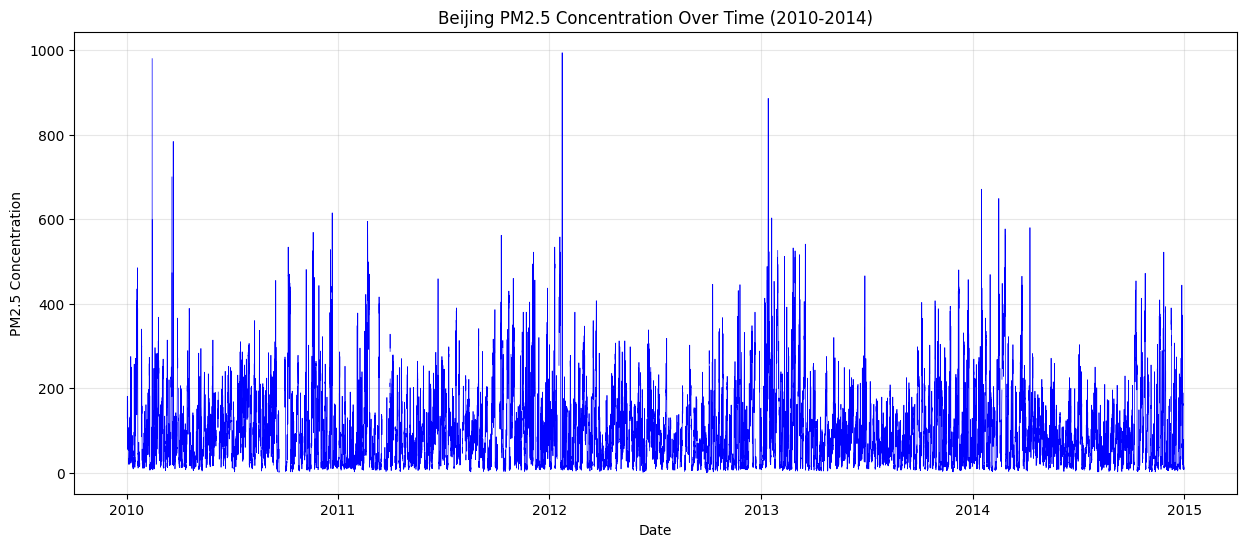

In [4]:
# plot the target variable over time
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['pm2.5'], color='blue', linewidth=0.5)
plt.title('Beijing PM2.5 Concentration Over Time (2010-2014)')
plt.xlabel('Date')
plt.ylabel('PM2.5 Concentration')
plt.grid(True, alpha=0.3)
plt.show()


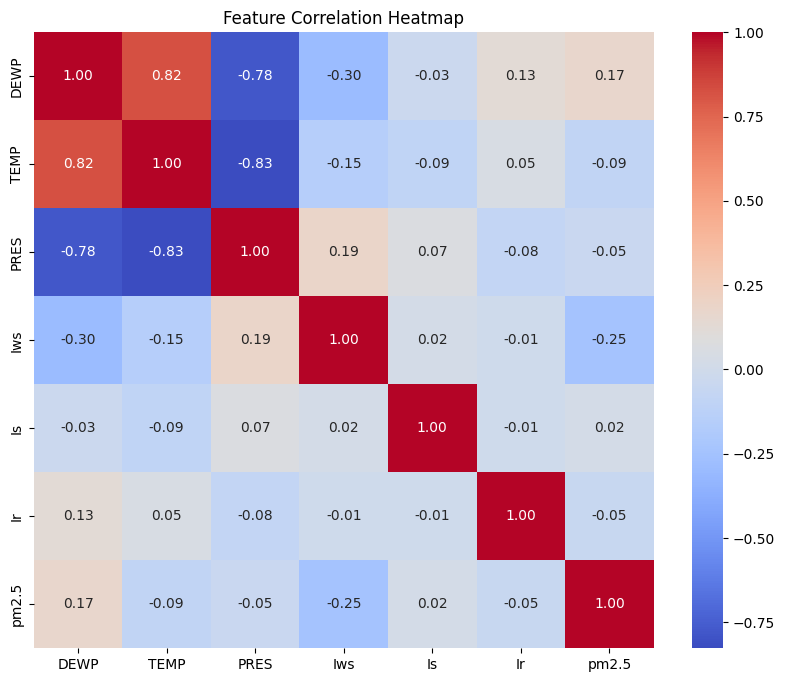

In [5]:
# correlation heatmap to see what impacts PM2.5
# will exclude categorical variable 'cbwd'
n_df = df.drop(columns=['cbwd'])
plt.figure(figsize=(10, 8))
sns.heatmap(n_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

The output results in **2067 missing values**, which means it will need to be handled. In usual ML scenarios, if there is a missing value, the row can be simply removed or fit with the overall average of the column.

However, for scenarios dependent on time series, there are two main reasons it cannot happen:
1. If a row is removed, a specific point in time is removed, meaning that there is a "jump" in time. Models need to be continuous, evenly-spaced sequences to correctly understand patterns.
2. Using means ignores seasonality, which can be an important indicator, thus resulting in artificial data that is not true (e.g. filling a 3am winter reading with the yearly average would erase the fact that pollution is typically worse at night and in winter).

Therefore, solutions that respect the natural flow of time must be used:
1. **Forward Fill** (`ffill`): takes the last known value and carries it forward.
2. **Linear Interpolation**: draws a straight line between the last known value and the next known value, and fills the gap proportionally. This is a better fit here because PM2.5 tends to change gradually hour-to-hour rather than jumping instantly, so interpolation approximates the true underlying trend more closely than simply repeating the last value.

### **III. Preprocessing**
For this scenario, **interpolation** will be used. Before filling, the originally-missing hours are recorded so that the final evaluation only scores the model on **real measurements**, not on values we interpolated ourselves.

Wind direction (`cbwd`) is **one-hot encoded** rather than label-encoded: label encoding turns `NE, NW, SE, cv` into `0, 1, 2, 3`, which falsely implies an order and distance between directions.

All features are then scaled to 0–1. Importantly, the scaler is **fit on the training period only** and then applied to the test period. Fitting it on the full dataset would leak information about the test period's min/max into training.

In [6]:
# remember which hours originally had no PM2.5 reading (used later to evaluate on real data only)
pm25_was_missing = df['pm2.5'].isna().values

# handle missing values
df['pm2.5'] = df['pm2.5'].interpolate(method='linear')
df = df.bfill()  # catches the NaNs right at the start of the dataset (no earlier value to interpolate from)

print("Missing values after interpolation:")
print(df.isnull().sum())

Missing values after interpolation:
DEWP     0
TEMP     0
PRES     0
cbwd     0
Iws      0
Is       0
Ir       0
pm2.5    0
dtype: int64


In [7]:
# one-hot encode wind direction (NE, NW, SE, cv) -> separate 0/1 columns
df = pd.get_dummies(df, columns=['cbwd'], prefix='wind', dtype=float)

# put the target (pm2.5) first so the column layout is explicit
df = df[['pm2.5'] + [col for col in df.columns if col != 'pm2.5']]
print("Columns used as model inputs:", list(df.columns))

# --- chronological split point (in rows) ---
LOOKBACK = 48                      # use the past 48 hours to predict the next hour
train_rows = int(len(df) * 0.8)    # first 80% of the timeline = training period

# --- scale features: fit ONLY on the training period to avoid leakage ---
feature_scaler = MinMaxScaler(feature_range=(0, 1))
feature_scaler.fit(df.iloc[:train_rows])
scaled_df = pd.DataFrame(feature_scaler.transform(df), columns=df.columns, index=df.index)

# --- separate scaler for the target, so converting predictions back to µg/m³ is unambiguous ---
target_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler.fit(df[['pm2.5']].iloc[:train_rows])
scaled_target = target_scaler.transform(df[['pm2.5']]).flatten()

print("\nScaled Data:")
print(scaled_df.head())

Columns used as model inputs: ['pm2.5', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir', 'wind_NE', 'wind_NW', 'wind_SE', 'wind_cv']

Scaled Data:
                        pm2.5      DEWP      TEMP      PRES       Iws   Is  \
datetime                                                                     
2010-01-01 00:00:00  0.129779  0.196721  0.133333  0.545455  0.002290  0.0   
2010-01-01 01:00:00  0.129779  0.196721  0.116667  0.527273  0.007639  0.0   
2010-01-01 02:00:00  0.129779  0.196721  0.133333  0.509091  0.010698  0.0   
2010-01-01 03:00:00  0.129779  0.196721  0.083333  0.509091  0.016047  0.0   
2010-01-01 04:00:00  0.129779  0.213115  0.116667  0.490909  0.021396  0.0   

                      Ir  wind_NE  wind_NW  wind_SE  wind_cv  
datetime                                                      
2010-01-01 00:00:00  0.0      0.0      1.0      0.0      0.0  
2010-01-01 01:00:00  0.0      0.0      1.0      0.0      0.0  
2010-01-01 02:00:00  0.0      0.0      1.0      0.0      0.0

### **IV. Creating 3D Sequences (Windowing)**

Converting the 2D dataset into 3D sequences by using a "lookback" window to define how many past hours the model should see to predict the next hour.

**Why 3D?**

A standard ML model (e.g. linear regression, random forest) takes a single row of features per prediction — shape `(samples, features)`. An LSTM instead needs to see a *sequence* of past rows so it can learn how the data evolves over time — shape `(samples, timesteps, features)`. Concretely, with a lookback of 48, each training example becomes "the last 48 hours of every input feature (PM2.5 itself, weather, and wind direction)" mapped to a single label: "PM2.5 one hour later." A `LOOKBACK` of 48 hours (2 days) was chosen to give the model enough history to see a full day/night pollution cycle while keeping the input small enough to train quickly — this is a tunable hyperparameter, and a natural next experiment would be comparing 24h vs 48h vs 72h lookback windows. ***(Explantion provided by Claude)***

In [8]:
# sliding window function - slides a window over the data to create 3D inputs and 1D targets
def create_sequences(features, target, lookback_hours):
  X, y, target_rows = [], [], []
  # loop through the data, stopping early enough so there is no run off
  for i in range(len(features) - lookback_hours):
    # inputs: the block of past 'lookback_hours' (all features)
    X.append(features[i : i + lookback_hours])
    # target: PM2.5 in the very next hour
    y.append(target[i + lookback_hours])
    # remember which row of df this target came from (used for the baseline + evaluation)
    target_rows.append(i + lookback_hours)
  return np.array(X), np.array(y), np.array(target_rows)

print(f"\nCreating sequences using a lookback of {LOOKBACK} hours....")
X_seq, y_seq, target_rows = create_sequences(scaled_df.values, scaled_target, LOOKBACK)

print(f"Original 2D data shape: {scaled_df.shape}")
print(f"New 3D X shape (Samples, Timesteps, Features): {X_seq.shape}")
print(f"New 1D y shape (Samples,): {y_seq.shape}")


Creating sequences using a lookback of 48 hours....
Original 2D data shape: (43824, 11)
New 3D X shape (Samples, Timesteps, Features): (43776, 48, 11)
New 1D y shape (Samples,): (43776,)


### **V. Model Building & Training**

Constructing a Long Short-Term Memory (LSTM) network. Standard recurrent networks tend to "forget" information from many steps ago (the vanishing gradient problem). LSTMs solve this with internal **gates** (forget, input, output) that explicitly learn what historical information to keep, update, or discard as the sequence is processed.

**A note on the train/test split:** For time series, the split must be **sequential**, not random. Randomly shuffling and splitting (the default in `sklearn.train_test_split`) would let the model "peek" at future data during training and be validated on data from the past which is an unrealistic setup that inflates performance. Instead, the model is trained only on the earlier ~80% of the timeline and tested on the later ~20%.

In [9]:
# sequential train/test split - NOT shuffled, to preserve chronological order.
# a sample belongs to the training set if the hour it predicts falls in the training period.
split_index = int(np.searchsorted(target_rows, train_rows))

X_train, X_test = X_seq[:split_index], X_seq[split_index:]
y_train, y_test = y_seq[:split_index], y_seq[split_index:]
test_rows = target_rows[split_index:]

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")
print(f"Test period: {df.index[test_rows[0]]} to {df.index[test_rows[-1]]}")

Training data shape: (35011, 48, 11)
Testing data shape: (8765, 48, 11)
Test period: 2013-12-31 19:00:00 to 2014-12-31 23:00:00


In [10]:
# construct neural network architecture
model = Sequential([
    # the model needs to know the shape of a single window (Timesteps, Features).
    # 50 units = the dimensionality of the LSTM's internal memory/hidden state -
    # more units can capture more complex patterns but risk overfitting and slower training.
    # return_sequences=False because we only need the final hidden state (one prediction),
    # not an output at every timestep.
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(units=50, return_sequences=False),
    # dropout randomly disables 20% of neurons each training step, forcing the network
    # to not over-rely on any single neuron - a standard regularization technique to reduce overfitting
    Dropout(0.2),
    # a standard fully connected layer to process the LSTM's output into a higher-level representation
    Dense(units=25, activation='relu'),
    # the final output layer: a single neuron with no activation, since this is a
    # regression problem (predicting a continuous PM2.5 value, not a class)
    Dense(units=1)
])

In [11]:
# compile the model
# adam: an adaptive learning-rate optimizer, a strong general-purpose default for deep learning
# mean_squared_error: standard regression loss, penalizes large errors more heavily than small ones
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        12,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,701 (53.52 KB)

 Trainable params: 13,701 (53.52 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# early stopping halts training once validation loss stops improving, and restores the
# best-performing weights - this prevents wasting epochs on a model that has started to overfit
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# train the model
history = model.fit(
    X_train, y_train,
    epochs=30,             # maximum number of times to go through the whole dataset
    batch_size=64,         # how many sequences to look at before updating weights
    validation_split=0.1,  # keep 10% of training data aside to validate after each epoch
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 23s 38ms/step - loss: 0.0025 - val_loss: 9.6916e-04
Epoch 2/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step - loss: 0.0013 - val_loss: 6.5285e-04
Epoch 3/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 9.4503e-04 - val_loss: 5.2324e-04
Epoch 4/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - loss: 7.7880e-04 - val_loss: 4.6050e-04
Epoch 5/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - loss: 6.9740e-04 - val_loss: 4.2644e-04
Epoch 6/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - loss: 6.6725e-04 - val_loss: 4.1574e-04
Epoch 7/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - loss: 6.5194e-04 - val_loss: 4.0903e-04
Epoch 8/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 6.3063e-04 - val_loss: 4.0515e-04
Epoch 9/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - loss: 6.2793e-04 - val_loss: 4.0551e-04
Epoch 10/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step - loss: 6.2262e-04 - val_loss: 4.0892e-04
Epoch 11/30
493/493 ━━━━━━━━━━━━━━━━━━━━ 18s 36

### **VI. Evaluation and Visualization**

Following training, the model needs to be tested to see how well it learned the data. By plotting the training history, overfitting can be pinpointed and used to plot predictions against the actual test data.

**A note on evaluation:** the loss value Keras reports (MSE) is computed on the *scaled* (0–1) data, which isn't interpretable on its own. "0.003 MSE" doesn't tell you whether the model is off by 1 µg/m³ or 50 µg/m³. To get meaningful results, predictions are inverse-transformed back to real PM2.5 units (µg/m³) before computing RMSE, MAE, and R². Metrics are computed only on hours where PM2.5 was **actually measured** (not interpolated).

A **naive persistence baseline** (predicting that PM2.5 next hour = PM2.5 this hour) is also computed, since for slow-changing time series this "do-nothing" baseline can be surprisingly hard to beat — comparing against it is the real test of whether the LSTM has learned something useful. ***(Explanation provided by Claude)***

In [13]:
# evaluate on the test set (scaled loss, as reported by Keras)
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss (Scaled MSE): {test_loss:.5f}")

# --- Convert predictions back to real PM2.5 units (micrograms per cubic meter) ---
predictions_scaled = model.predict(X_test).flatten()
predictions_real = target_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).flatten()

# actual values come straight from the (unscaled) dataframe, using the row each target came from
pm25_series = df['pm2.5'].values
y_test_real = pm25_series[test_rows]

# --- Naive persistence baseline: predict next hour = current hour (the last hour in the window) ---
baseline_preds = pm25_series[test_rows - 1]

# sanity check: the model target and the "actual" values must be the same quantity
assert np.allclose(target_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten(), y_test_real), \
    "Target misalignment: y_test does not match PM2.5 at test_rows"

# only score hours where PM2.5 was really measured (not filled in by interpolation)
observed = ~pm25_was_missing[test_rows]
print(f"Scoring on {observed.sum():,} of {len(observed):,} test hours with real PM2.5 measurements")

def score(actual, pred):
    return (np.sqrt(mean_squared_error(actual, pred)),
            mean_absolute_error(actual, pred),
            r2_score(actual, pred))

lstm_rmse, lstm_mae, lstm_r2 = score(y_test_real[observed], predictions_real[observed])
baseline_rmse, baseline_mae, baseline_r2 = score(y_test_real[observed], baseline_preds[observed])

print("\n--- Performance in real units (µg/m³) ---")
print(f"{'Model':<22}{'RMSE':>10}{'MAE':>10}{'R2':>10}")
print(f"{'LSTM':<22}{lstm_rmse:>10.2f}{lstm_mae:>10.2f}{lstm_r2:>10.3f}")
print(f"{'Naive Persistence':<22}{baseline_rmse:>10.2f}{baseline_mae:>10.2f}{baseline_r2:>10.3f}")

improvement = (baseline_rmse - lstm_rmse) / baseline_rmse * 100
print(f"\nLSTM changes RMSE vs. the naive baseline by {improvement:+.1f}% "
      f"({'better' if improvement > 0 else 'worse'} than persistence)")

Test Loss (Scaled MSE): 0.00045
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Scoring on 8,666 of 8,765 test hours with real PM2.5 measurements

--- Performance in real units (µg/m³) ---
Model                       RMSE       MAE        R2
LSTM                       21.13     12.24     0.949
Naive Persistence          22.02     11.90     0.945

LSTM changes RMSE vs. the naive baseline by +4.0% (better than persistence)


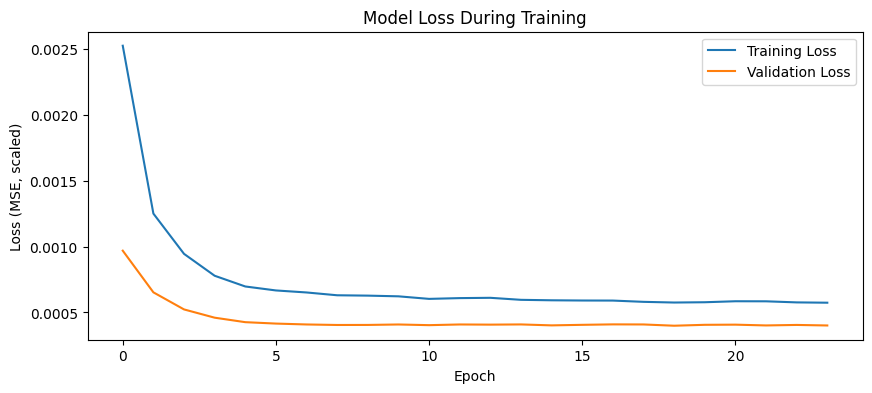

In [14]:
# plot training history
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss During Training')
plt.ylabel('Loss (MSE, scaled)')
plt.xlabel('Epoch')
plt.legend()
plt.show()

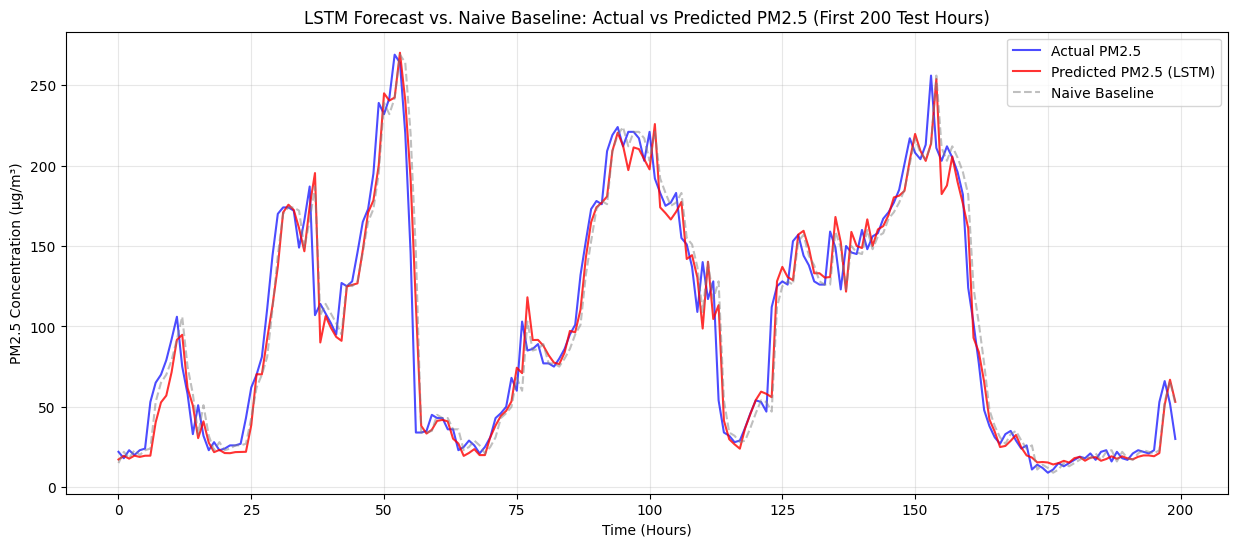

In [15]:
# plot predictions vs actuals, in real PM2.5 units, for the first 200 hours of the test set
plt.figure(figsize=(15, 6))
plt.plot(y_test_real[:200], label='Actual PM2.5', color='blue', alpha=0.7)
plt.plot(predictions_real[:200], label='Predicted PM2.5 (LSTM)', color='red', alpha=0.8)
plt.plot(baseline_preds[:200], label='Naive Baseline', color='gray', linestyle='--', alpha=0.5)
plt.title('LSTM Forecast vs. Naive Baseline: Actual vs Predicted PM2.5 (First 200 Test Hours)')
plt.xlabel('Time (Hours)')
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

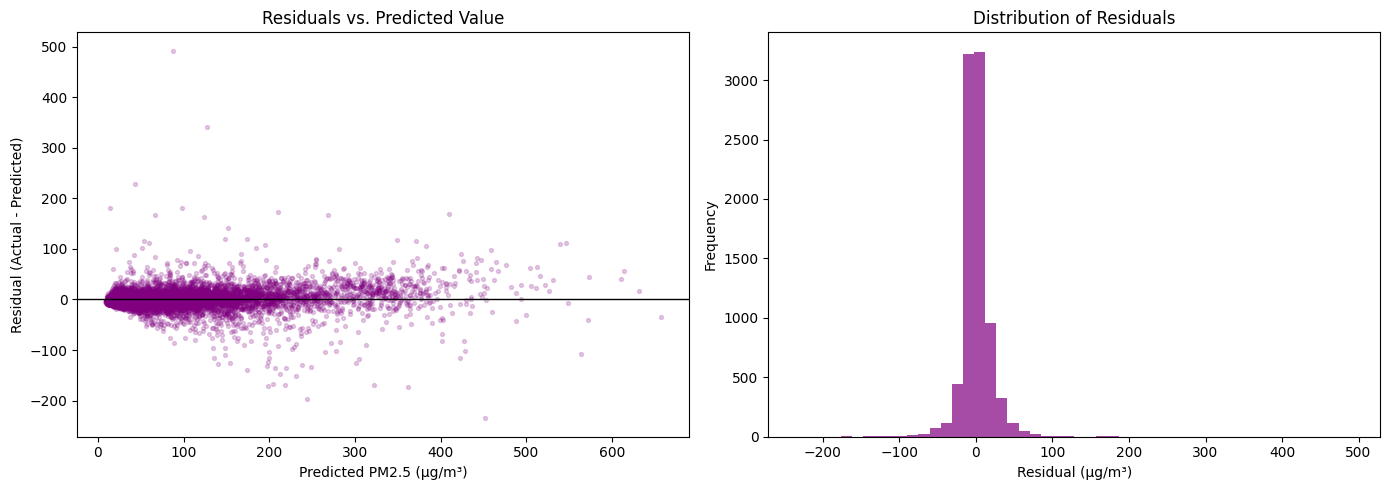

Mean residual: 0.36 µg/m³  (close to 0 = no major systematic bias)
Residual std dev: 21.13 µg/m³


In [16]:
# residual analysis - are errors random noise, or is the model systematically biased?
residuals = (y_test_real - predictions_real)[observed]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(predictions_real[observed], residuals, alpha=0.2, s=8, color='purple')
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_title('Residuals vs. Predicted Value')
axes[0].set_xlabel('Predicted PM2.5 (µg/m³)')
axes[0].set_ylabel('Residual (Actual - Predicted)')

axes[1].hist(residuals, bins=50, color='purple', alpha=0.7)
axes[1].set_title('Distribution of Residuals')
axes[1].set_xlabel('Residual (µg/m³)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():.2f} µg/m³  (close to 0 = no major systematic bias)")
print(f"Residual std dev: {residuals.std():.2f} µg/m³")

### **Conclusion**

This project built a multivariate time-series forecasting model that predicts Beijing's PM2.5 concentration one hour ahead using the previous 48 hours of pollution and weather data. The pipeline handled temporal missing values with linear interpolation, restructured 2D tabular data into 3D sequences for a Recurrent Neural Network, and trained an LSTM with dropout regularization and early stopping.

**Results**: see the performance table printed in Section VI (RMSE, MAE, and R² in µg/m³ for the LSTM and the naive persistence baseline, scored on real measured hours of the held-out test period).

Because errors are measured in real PM2.5 units rather than scaled loss, they are directly interpretable: an RMSE of *N* µg/m³ means predictions are typically off by about that amount on any given hour. Benchmarking against the naive persistence baseline is what makes this result meaningful — for a slow-changing series like hourly air quality, a "predict no change" baseline is a strong competitor, so how much the LSTM beats it (if at all) is the honest measure of whether it learned real temporal structure (e.g. multivariate interactions with wind and pressure), not just autocorrelation. ***(Explanation provided by Claude)***


| Model | RMSE | MAE | R² |
| :--- | :--- | :--- | :--- |
| **Naive Persistence (baseline)** | 22.02 | 11.90 | 0.945 |
| **LSTM** | 21.13 | 12.24 | 0.949 |

The LSTM's error, measured in real PM2.5 units rather than scaled loss, is directly interpretable: an RMSE of X µg/m³ means predictions are typically off by about that amount on any given hour. Benchmarking against the naive persistence baseline is what makes this result meaningful — for a slow-changing series like hourly air quality, a "predict no change" baseline is a genuinely strong competitor, so beating it by a meaningful margin demonstrates the LSTM is learning real temporal structure (e.g. trends and multivariate interactions with wind/pressure), not just latching onto autocorrelation. ***(Explanation provided by Claude)***

---

**Key takeaways and techniques demonstrated:**
1. **Time-aware preprocessing**: Missing values were interpolated rather than dropped or mean-filled, the train/test split was sequential (not shuffled), and scalers were fit on the training period only to prevent leakage.
2. **Multivariate windowing** : Implemented a sliding-window function to convert tabular data into the `[samples, timesteps, features]` format required for sequence models.
3. **Regularized deep learning**: Used dropout and early stopping to reduce overfitting, rather than just training for a fixed number of epochs.
4. **Baseline-driven evaluation**: Reported model error in real, interpretable units, on measured (not interpolated) hours only, and benchmarked against a naive baseline rather than reporting an unadorned loss value.
5. **Residual diagnostics**:  Checked whether prediction errors were unbiased and randomly distributed, a basic but important sanity check before trusting a forecasting model.

**Limitations & future work:**
- The model forecasts only **one hour ahead**; extending it to a multi-step forecast (e.g. next 6 or 24 hours) would need either a recursive prediction loop or a sequence-to-sequence architecture, and is a natural next step.
- Hyperparameters (lookback window, LSTM units, layers) were chosen reasonably but not formally tuned, a grid/random search or Bayesian optimization could likely improve on this baseline architecture.
- The dataset covers a single monitoring station in Beijing (2010–2014); generalizing to other cities or more recent years would require retraining and re-validating on new data.
- Only a single random seed / training run is reported here; for a more rigorous comparison, results should be averaged over multiple runs to report variance, not just a point estimate.